In [1]:
import scanpy as sc
import scvelo as scv
import sys
import pandas as pd
import torch
import os.path
import topovelo as tpv
import numpy as np

In [2]:
csv_dir ="/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/00csv/"
h5ad_dir ="/DATA/User/liqian7/pienapple/04AS_updata/00data/h5ad_RAw/"
dataset = 'slide-seq-adult-cortex'
data_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
figure_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
model_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
dataset = 'slide-seq-adult-cortex'
data_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
main_figure_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
main_model_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'

In [127]:
key="SS200000709TR_D1_1"
key1=key[:-2]

In [128]:
df = pd.read_csv(csv_dir+key+".csv",index_col=0)
data = sc.read_h5ad(h5ad_dir+key1+"_cell_gene.h5ad")
data.obs.index=data.obs.index.astype("int64")
data.obs=pd.merge(data.obs,df,right_index=True,left_index=True,how="left")
data.obs=data.obs.fillna("others")
data.obs.index=data.obs.index.astype("object")
data1=data[data.obs['Celltype'].isin(['Macro.','SMCs','mSMCss'])]
data1.obs.index=data1.obs.index.astype("int64")

In [129]:
data1

View of AnnData object with n_obs × n_vars = 7923 × 28686
    obs: 'area', 'x_x', 'y_x', 'Rownames', 'nCount_RNA', 'nFeature_RNA', 'Chip', 'Chip ID', 'x_y', 'y_y', 'Location', 'GC_LC', 'Aortic Area', 'Digitization Layer', 'Digitization Column', 'Plaque Score', 'Celltype', 'First_ratio', 'Second_ratio', 'Ann class1', 'Ann class2', 'Ann class3', 'Macro. ann1', 'Macro. ann2', 'Week', 'Week ID', 'rown', 'ann1', 'ann2', 'ann3', 'tissue1', 'sample', 'stage', 'cd', 'layer'
    uns: '__type', 'pp', 'seg', 'spatial'
    obsm: 'bbox', 'contour', 'spatial'
    layers: 'spliced', 'unspliced'

In [130]:
df = pd.read_csv(csv_dir+key+".csv",index_col=0)
data = sc.read_h5ad(h5ad_dir+key1+"_cell_gene.h5ad")
data.obs.index=data.obs.index.astype("int64")
data.obs=pd.merge(data.obs,df,right_index=True,left_index=True,how="left")
# data.obs=data.obs.fillna("others")
data.obs.index=data.obs.index.astype("object")
data1=data[data.obs['GC_LC'].isin(["LC","GC"])]
data1.obs.index=data1.obs.index.astype("int64")

In [131]:
adata =data1
adata.obsm["X_spatial"]=adata.obsm["spatial"]
adata.obs['clusters']=adata.obs['Celltype']

In [132]:
tpv.preprocess(adata,
               n_gene=200,
               spatial_key='X_spatial',
               min_count_per_cell=1,
               min_genes_expressed=1,
               compute_umap=True)

Filtered out 28526 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
Skip filtering by dispersion since number of variables are less than `n_top_genes`.
Run PCA.
Computing the KNN graph based on X_pca
computing neighbors
    finished (0:00:03) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
Keep raw unspliced/spliced count data.
Computing UMAP coordinates.


In [134]:
tpv.build_spatial_graph(
    adata,
    spatial_key='X_spatial',
    graph_key='spatial_graph',
    method='BallTree',
    radius=30
)

Ball Tree: average number of neighbors: 4.9


In [ ]:
tpv.plotting.plot_spatial_graph(adata, graph_key='spatial_graph', basis='spatial', width=4,node_size=3)

In [136]:
# Set paths to save figures and model parameters
adata_path = '/DATA/User/liqian7/pienapple/15human_fn/17topvelo/00mouse/test/'
# Set paths to save figures and model parameters
figure_path = f'{main_figure_path}/gat'
model_path = f'{main_model_path}/gat'

In [137]:
vae = tpv.VAE(
    adata, 
    tmax=20, 
    dim_z=5, 
    hidden_size=(50, 25, 50),
    device='cuda:0',
    graph_decoder=True,
    attention=True
)

Estimating ODE parameters...


  0%|          | 0/160 [00:00<?, ?it/s]

  0%|          | 0/160 [00:00<?, ?it/s]

Reinitialize the regular ODE parameters based on estimated global latent time.


  0%|          | 0/160 [00:00<?, ?it/s]

In [ ]:
config = {
    'learning_rate': 2e-4,
    'learning_rate_ode': 5e-3,
    'learning_rate_refine': 2e-4
}
vae.train(
    adata,
    adata.obsp['spatial_graph'],
    'X_spatial',
    config=config,
    figure_path=figure_path
)

*********               Creating a Graph Dataset              *********
*********                      Finished.                      *********
--------------------------- Train a TopoVelo ---------------------------
*********                 Creating optimizers                 *********
*********                      Finished.                      *********
*********                    Start training                   *********
*********                      Stage  1                       *********
*********       Stage 1: Early Stop Triggered at epoch 128.       *********
Summary: 
Train ELBO = 290.139
Test ELBO = 293.055
Total Time =   0 h :  4 m : 43 s

*********                      Stage  2                       *********


Calculating KNN:   0%|          | 0/10162 [00:00<?, ?it/s]

In [75]:
vae.save_model(model_path, 'encoder', 'decoder')
vae.save_anndata(adata, 'gat', adata_path)

In [ ]:
import scanpy as sc
import numpy as np

# 假设您的 AnnData 对象是 adata

# # 1. 定义颜色映射字典 (直接从您的R代码转换而来)
# color_map = {
#     'EC': "#238b45",
#     'FBs': "#8b4a4b", 
#     'Macro.': "#df65b0",
#     'mSMCss': "#A1CFFA",
#     'SMCs': "#1f78b4",
#     'T cells': "#ce1256"
# }
color_map = {
    'Macro.': "#df65b0",
    'mSMCss': "#A1CFFA",
    'SMCs': "#1f78b4"
}

# 2. 获取分类的顺序 (这很重要，颜色必须按此顺序排列)
celltype_categories = adata.obs['Celltype'].cat.categories

# 3. 按照 categories 的顺序从 color_map 中提取对应的颜色
#    这样能确保颜色和类别的顺序严格匹配
colors_ordered = [color_map[ct] for ct in celltype_categories]

# 4. 将颜色列表存入 adata.uns 中
adata.uns['Celltype_colors'] = colors_ordered

# 可选：验证一下结果
print("细胞类型顺序:", list(celltype_categories))
print("对应颜色顺序:", adata.uns['Celltype_colors'])

In [ ]:
import scanpy as sc
import numpy as np

# 假设您的 AnnData 对象是 adata

# 1. 定义颜色映射字典 (直接从您的R代码转换而来)
color_map = {
    'EC': "#238b45",
    'FBs': "#8b4a4b", 
    'Macro.': "#df65b0",
    'mSMCss': "#A1CFFA",
    'SMCs': "#1f78b4",
    'T cells': "#ce1256"
}

# 2. 获取分类的顺序 (这很重要，颜色必须按此顺序排列)
celltype_categories = adata.obs['clusters'].cat.categories

# 3. 按照 categories 的顺序从 color_map 中提取对应的颜色
#    这样能确保颜色和类别的顺序严格匹配
colors_ordered = [color_map[ct] for ct in celltype_categories]

# 4. 将颜色列表存入 adata.uns 中
adata.uns['clusters_colors'] = colors_ordered

# 可选：验证一下结果
print("细胞类型顺序:", list(celltype_categories))
print("对应颜色顺序:", adata.uns['clusters_colors'])

In [ ]:
colors_ordered

In [ ]:
adata.uns['clusters_colors']

In [ ]:
adata.uns['clusters_colors']

In [ ]:
#####eva
scv.pl.scatter(adata, basis='spatial')

In [ ]:
adata

In [ ]:

cluster_edges = [('SMCs',"mSMCss"), ("mSMCss","Macro."),('SMCs',"Macro.")]

# x axis indicates the developmental time due to layered growth
x = -adata.obsm['X_spatial'][:, 0]
tprior = 20 * (x - x.min())/(x.max() - x.min())
adata.obs['tprior'] = adata.obs['layer']

res = tpv.post_analysis(
    adata,
    'cortex',
    ['TopoVelo (GAT)'],
    ['gat'],
    cluster_edges=cluster_edges,
    spatial_velocity_graph=True,
    n_spatial_neighbors=50,
    spatial_key='X_spatial',
    spatial_graph_key='spatial_graph',
    compute_metrics=True,
    embed='spatial',
    plot_type=[]
)

In [85]:
res[1]

Model              TopoVelo (GAT)                                              \
                   SMCs -> mSMCss mSMCss -> Macro. mSMCss -> FBs mSMCss -> EC   
CBDir (Gene Space)         -0.010            0.071         0.003        0.075   
CBDir                      -0.010            0.015        -0.261        0.115   
Time Score                  0.479            0.366         0.307        0.331   

Model                         
                   FBs -> EC  
CBDir (Gene Space)     0.075  
CBDir                  0.052  
Time Score             0.534

In [86]:
res[2]

Model                                TopoVelo (GAT)                    \
                                             1-step   2-step   3-step   
K-CBDir (Gene Space)                         -0.121   -0.107   -0.082   
K-CBDir                                      -0.358   -0.334   -0.274   
Mann-Whitney Test (Gene Space)                0.043    0.116    0.228   
Mann-Whitney Test                             0.052    0.158    0.274   
Mann-Whitney Test Stats (Gene Space)         95.010  205.217  287.283   
Mann-Whitney Test Stats                      94.991  203.465  286.068   

Model                                                   
                                       4-step   5-step  
K-CBDir (Gene Space)                   -0.060   -0.043  
K-CBDir                                -0.225   -0.189  
Mann-Whitney Test (Gene Space)          0.308    0.355  
Mann-Whitney Test                       0.348    0.389  
Mann-Whitney Test Stats (Gene Space)  340.190  373.893  
Mann-Whitney Test Stats               337.943  370.596

In [87]:
res[3]

Model                                TopoVelo (GAT)                    \
Transition                           SMCs -> mSMCss                     
Step                                         1-step   2-step   3-step   
K-CBDir (Gene Space)                         -0.123   -0.120   -0.109   
K-CBDir                                      -0.371   -0.364   -0.338   
Mann-Whitney Test (Gene Space)                0.036    0.077    0.147   
Mann-Whitney Test                             0.055    0.127    0.200   
Mann-Whitney Test Stats (Gene Space)         73.888  147.582  211.747   
Mann-Whitney Test Stats                      75.136  148.722  213.552   

Model                                                                    \
Transition                                             mSMCss -> Macro.   
Step                                   4-step   5-step           1-step   
K-CBDir (Gene Space)                   -0.099   -0.090           -0.150   
K-CBDir                                -0.312   -0.289           -0.386   
Mann-Whitney Test (Gene Space)          0.213    0.250            0.037   
Mann-Whitney Test                       0.253    0.299            0.033   
Mann-Whitney Test Stats (Gene Space)  257.727  288.957          198.217   
Mann-Whitney Test Stats               258.527  289.078          200.665   

Model                                                                     ...  \
Transition                                                                ...   
Step                                   2-step   3-step   4-step   5-step  ...   
K-CBDir (Gene Space)                   -0.085    0.007    0.064    0.099  ...   
K-CBDir                                -0.253   -0.036    0.104    0.188  ...   
Mann-Whitney Test (Gene Space)          0.327    0.659    0.802    0.857  ...   
Mann-Whitney Test                       0.340    0.659    0.794    0.848  ...   
Mann-Whitney Test Stats (Gene Space)  438.737  584.829  656.428  692.988  ...   
Mann-Whitney Test Stats               436.528  586.772  661.131  701.030  ...   

Model                                                                         \
Transition                           mSMCss -> EC                              
Step                                       1-step   2-step   3-step   4-step   
K-CBDir (Gene Space)                       -0.135   -0.132   -0.129   -0.122   
K-CBDir                                    -0.336   -0.347   -0.351   -0.346   
Mann-Whitney Test (Gene Space)              0.064    0.076    0.106    0.109   
Mann-Whitney Test                           0.086    0.149    0.201    0.242   
Mann-Whitney Test Stats (Gene Space)       61.659  125.023  172.431  214.024   
Mann-Whitney Test Stats                    64.015  132.026  181.063  214.755   

Model                                                                     \
Transition                                    FBs -> EC                    
Step                                   5-step    1-step  2-step   3-step   
K-CBDir (Gene Space)                   -0.118    -0.048  -0.049   -0.053   
K-CBDir                                -0.341    -0.228  -0.251   -0.258   
Mann-Whitney Test (Gene Space)          0.129     0.047   0.047    0.063   
Mann-Whitney Test                       0.240     0.046   0.079    0.111   
Mann-Whitney Test Stats (Gene Space)  241.219    48.880  84.100  115.214   
Mann-Whitney Test Stats               235.290    49.102  86.308  117.124   

Model                                                   
Transition                                              
Step                                   4-step   5-step  
K-CBDir (Gene Space)                   -0.050   -0.047  
K-CBDir                                -0.258   -0.258  
Mann-Whitney Test (Gene Space)          0.067    0.070  
Mann-Whitney Test                       0.128    0.139  
Mann-Whitney Test Stats (Gene Space)  141.899  164.323  
Mann-Whitney Test Stats               145.253  167.211  

[6 rows x 25 col

In [88]:
###Step 1: create a PerfLogger object
perf_logger = tpv.PerfLogger(save_path=adata_path)

In [89]:
dataset_name = 'test'
perf_logger.insert(dataset_name, *res)

In [90]:
perf_logger.save('benchmark')

In [ ]:
metrics = ['Time Correlation',
           'CBDir',
           'MSE Test',
           'Spatial Velocity Consistency',
           'Spatial Time Consistency']
perf_logger.plot(metrics,
                 legend_metric='CBDir',
                 figsize=(10, 5),
                 title_fontsize=12,
                 legend_fontsize=8,
                 ylabel_fontsize=8,
                 labelpad=0,
                 tick_fontsize=7,
                 hspace=0.5,
                 wspace=0.2,
                 ncols_legend=1,
                 bbox_to_anchor=(0, 1.0, 1.0, 0.02),
                 figure_path=figure_path,
                 figure_name='perf',
                 dpi=300,
                 save_format='png')

In [ ]:
perf_logger.plot_velocity_metrics(metrics=['K-CBDir'], figure_path=figure_path)

In [ ]:
perf_logger.plot_summary(metrics=['K-CBDir'], figure_path=figure_path)

In [94]:
sc.pp.highly_variable_genes(adata)

In [95]:
print(adata.var.columns)


Index(['init_mode', 'w_init', 'gat_alpha', 'gat_beta', 'gat_gamma', 'gat_ton',
       'gat_scaling_u', 'gat_scaling_s', 'gat_sigma_u', 'gat_sigma_s',
       'gat_mse_train', 'gat_mse_test', 'gat_mae_train', 'gat_mae_test',
       'gat_likelihood_train', 'gat_likelihood_test', 'highly_variable',
       'means', 'dispersions', 'dispersions_norm'],
      dtype='object')


In [96]:
# define genes to plot
genes = tpv.sample_genes(adata, 4, 'highly_variable')

# compute figure size based on real aspect ratio
width = 4
figsize = tpv.compute_figsize(adata.obsm['X_spatial'], real_aspect_ratio=True, width=width)

cluster_plot_config={
    'figsize': figsize,
    'real_aspect_ratio':True
}
phase_plot_config={
    'width': 4
}
gene_plot_config={
    'width': 4
}
time_plot_config={
    'width': 4,
    'color_map': 'viridis',
}
stream_plot_config={
    'width': figsize[0],
    'height': figsize[1],
    'markersize': 100,
    'density': 2,
    'linewidth': 2,
}

In [ ]:
tpv.plotting.plot_spatial_graph(adata, graph_key='spatial_graph', basis='spatial', width=4)

In [ ]:
tpv.post_analysis(adata,
                  test_id='cortex',
                  methods=['TopoVelo (GAT)'],
                  keys=['gat'],
                  spatial_graph_key='spatial_graph',
                  spatial_velocity_graph=True,
                  n_spatial_neighbors=50,
                  spatial_key='X_spatial',
                  compute_metrics=False,dpi=300,
    figure_path="test.pdf",
                  embed='spatial',
                  cluster_plot_config=cluster_plot_config,
                  phase_plot_config=phase_plot_config,
                  gene_plot_config=gene_plot_config,
                  time_plot_config=time_plot_config,
                  stream_plot_config=stream_plot_config,
                  plot_type=['time', 'gene', 'phase', 'cluster', 'cell velocity'])

In [ ]:
tpv.post_analysis(adata,
                  test_id='cortex',
                  methods=['TopoVelo (GAT)'],
                  keys=['gat'],
                  spatial_graph_key='spatial_graph',
                  spatial_velocity_graph=True,
                  n_spatial_neighbors=50,
                  spatial_key='X_spatial',
                  compute_metrics=False,dpi=300,
    figure_path="test1",
                  embed='spatial',
                  cluster_plot_config=cluster_plot_config)

In [109]:
?stream_plot_config

Type:        dict
String form: {'width': 3, 'real_aspect_ratio': True, 'markersize': 30, 'density': 1, 'palette': ['#238b45', '#8b4a4b', '#df65b0', '#A1CFFA', '#1f78b4', '#ce1256']}
Length:      5
Docstring:  
dict() -> new empty dictionary
dict(mapping) -> new dictionary initialized from a mapping object's
    (key, value) pairs
dict(iterable) -> new dictionary initialized as if via:
    d = {}
    for k, v in iterable:
        d[k] = v
dict(**kwargs) -> new dictionary initialized with the name=value pairs
    in the keyword argument list.  For example:  dict(one=1, two=2)

In [124]:
color_map = {
    'EC': "#238b45", 
    'FBs': "#8b4a4b", 
    'Macro.': "#df65b0", 
    'SMCs': "#1f78b4", 
    'T cells': "#ce1256" ,
    'mSMCss': "#A1CFFA"
}
palette = list(color_map.values())
stream_plot_config = {
    'width': 10,
    'real_aspect_ratio': True,
    'markersize': 30,
    'density': 7,
    'palette': palette
}

---   Plotting  Results   ---


Computing a spatial graph using KNN on spatial with k=50
computing neighbors
    finished (0:00:03) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing velocity graph (using 5/96 cores)


  0%|          | 0/10162 [00:00<?, ?cells/s]

    finished (0:00:09) --> added 
    'gat_velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:01) --> added
    'gat_velocity_spatial', embedded velocity vectors (adata.obsm)
saving figure to file test1/vel-xy-cortex-gat.png


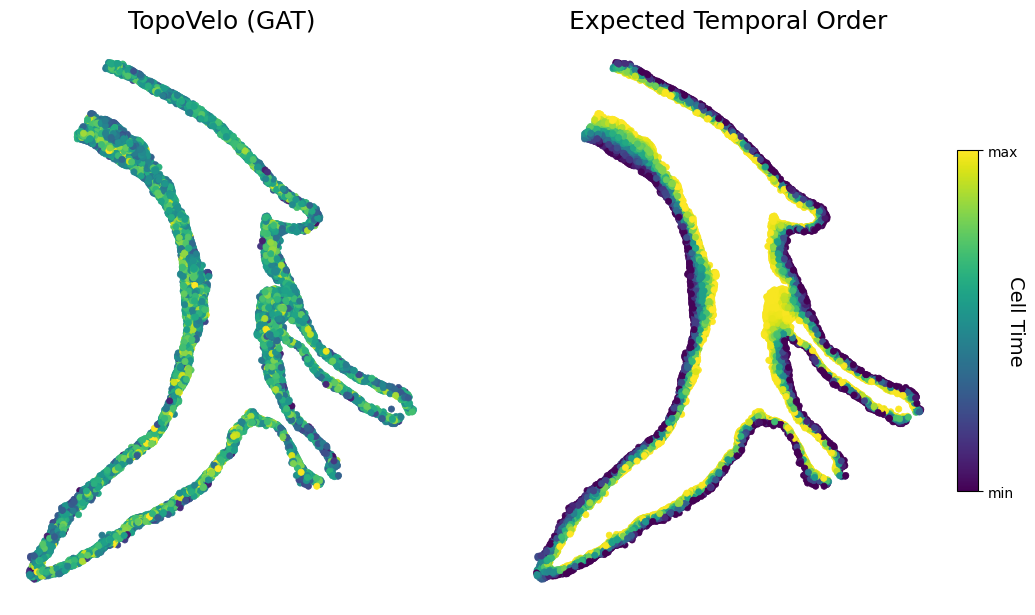

Recovering the original KNN graph from .uns


(None, None, None, None)

In [125]:
tpv.post_analysis(adata,
                  test_id='cortex',
                  methods=['TopoVelo (GAT)'],
                  keys=['gat'],
                  spatial_graph_key='spatial_graph',
                  spatial_velocity_graph=True,
                  n_spatial_neighbors=50,
                  spatial_key='X_spatial',
                  compute_metrics=False,dpi=800,
    figure_path="test1",
                  embed='spatial',plot_type=['time', 'cell velocity'],
    stream_plot_config=stream_plot_config,
                  cluster_plot_config=cluster_plot_config)